# 66 · Decision Transformer from scratch: control as return-conditioned sequence modeling

In [1]:
import os, copy, time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from vlacourse.rl_envs import PendulumEnv
from vlacourse.rl_algos import SquashedGaussianActor, evaluate_policy
from vlacourse import rl_algos

torch.set_num_threads(4)
device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("generated", exist_ok=True)
K, SCALE = 20, 100.0

def sac_snapshots(steps=(1500, 4000, 8000, 20000)):
    snaps, env = {}, PendulumEnv()
    for s in steps:
        snaps[s] = rl_algos.sac(PendulumEnv(), total_steps=s, start=1000, seed=0)
    return snaps

def collect(actor, n, noise, seed):
    env, eps = PendulumEnv(), []
    rng = np.random.default_rng(seed)
    for e in range(n):
        o, _ = env.reset(seed=seed + e); O, A, R = [], [], []; done = False
        while not done:
            a = env.action_space.sample() if actor is None else np.clip(actor.act(o) + rng.normal(0, noise, 1), -1, 1)
            O.append(o); A.append(a); o, r, te, tr, _ = env.step(a); R.append(r); done = te or tr
        eps.append(dict(obs=np.array(O, np.float32), act=np.array(A, np.float32), rew=np.array(R, np.float32)))
    return eps

def rtg(r):
    return np.cumsum(r[::-1])[::-1].copy()

class DecisionTransformer(nn.Module):
    def __init__(self, obs_dim=3, act_dim=1, d=128, n_layer=3, n_head=4, max_ep_len=200, K=K, discrete_bins=None):
        super().__init__()
        self.K, self.bins = K, discrete_bins
        self.emb_R, self.emb_s = nn.Linear(1, d), nn.Linear(obs_dim, d)
        self.emb_a = nn.Embedding(discrete_bins, d) if discrete_bins else nn.Linear(act_dim, d)
        self.emb_t = nn.Embedding(max_ep_len, d)
        layer = nn.TransformerEncoderLayer(d, n_head, 4 * d, dropout=0.1, batch_first=True, norm_first=True)
        self.tf = nn.TransformerEncoder(layer, n_layer)
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, discrete_bins if discrete_bins else act_dim)

    def forward(self, R, s, a, t):
        B, T = s.shape[:2]
        te = self.emb_t(t)
        a_in = self.emb_a(a)
        tokens = torch.stack([self.emb_R(R) + te, self.emb_s(s) + te, a_in + te], 2).reshape(B, 3 * T, -1)
        mask = torch.triu(torch.ones(3 * T, 3 * T, dtype=torch.bool, device=s.device), 1)
        h = self.ln(self.tf(tokens, mask=mask)).reshape(B, T, 3, -1)
        out = self.head(h[:, :, 1])
        return out if self.bins else torch.tanh(out)

def make_batches(eps, B, rng):
    R, S, A, T, M = [], [], [], [], []
    for _ in range(B):
        ep = eps[rng.integers(len(eps))]; L = len(ep["obs"]); st = rng.integers(0, L - 1)
        sl = slice(st, min(st + K, L)); n = sl.stop - sl.start; pad = K - n
        R.append(np.r_[np.zeros(pad), rtg(ep["rew"])[sl] / SCALE]); S.append(np.r_[np.zeros((pad, 3)), ep["obs"][sl]])
        A.append(np.r_[np.zeros((pad, 1)), ep["act"][sl]]); T.append(np.r_[np.zeros(pad, int), np.arange(st, st + n)]); M.append(np.r_[np.zeros(pad), np.ones(n)])
    f = lambda x, dt=torch.float32: torch.tensor(np.array(x), dtype=dt, device=device)
    return f(R)[..., None], f(S), f(A), f(T, torch.long), f(M)

def train_dt(eps, steps=6000, bins=None, seed=0):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    dt = DecisionTransformer(discrete_bins=bins).to(device)
    opt = torch.optim.AdamW(dt.parameters(), 1e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / 500))
    for step in range(steps):
        R, S, A, T, M = make_batches(eps, 64, rng)
        if bins:
            idx = ((A[..., 0] + 1) / 2 * bins).long().clamp(0, bins - 1)
            pred = dt(R, S, idx, T)
            loss = (nn.functional.cross_entropy(pred.reshape(-1, bins), idx.reshape(-1), reduction="none") * M.reshape(-1)).sum() / M.sum()
        else:
            loss = (((dt(R, S, A, T) - A) ** 2).mean(-1) * M).sum() / M.sum()
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(dt.parameters(), 0.25); opt.step(); sched.step()
    return dt

@torch.no_grad()
def rollout_dt(dt, target_return, seed=0):
    env = PendulumEnv(); o, _ = env.reset(seed=seed)
    R, S, A, T = [target_return / SCALE], [o], [np.zeros(1)], [0]
    total, done, t = 0.0, False, 0
    while not done:
        Rt = torch.tensor(np.array(R[-K:]), dtype=torch.float32, device=device)[None, :, None]
        St = torch.tensor(np.array(S[-K:]), dtype=torch.float32, device=device)[None]
        Tt = torch.tensor(np.array(T[-K:]), dtype=torch.long, device=device)[None]
        a_hist = np.array(A[-K:])
        if dt.bins:
            At = torch.tensor(np.clip(((a_hist[:, 0] + 1) / 2 * dt.bins).astype(int), 0, dt.bins - 1), device=device)[None]
            idx = dt(Rt, St, At, Tt)[0, -1].argmax().item()
            a = np.array([(idx + 0.5) / dt.bins * 2 - 1])
        else:
            a = dt(Rt, St, torch.tensor(a_hist, dtype=torch.float32, device=device)[None], Tt)[0, -1].cpu().numpy()
        A[-1] = a
        o, r, te, tr, _ = env.step(a); total += r; done = te or tr; t += 1
        R.append(R[-1] - r / SCALE); S.append(o); A.append(np.zeros(1)); T.append(min(t, 199))
    return total

offline dataset: 300 episodes, returns from -1903 to -1 (736s)


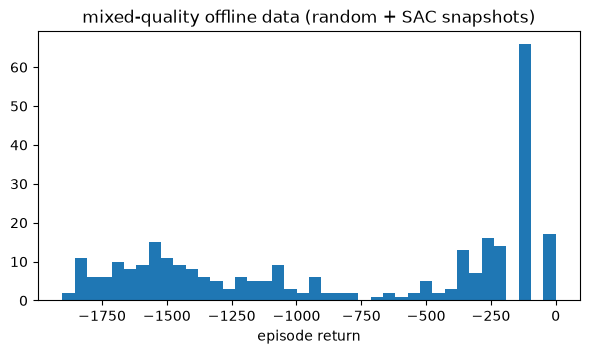

In [2]:
t0 = time.time()
snaps = sac_snapshots()
data = collect(None, 60, 0, 0)
for s, actor in snaps.items():
    data += collect(actor, 60, 0.3, s * 7)
returns = np.array([e["rew"].sum() for e in data])
print(f"offline dataset: {len(data)} episodes, returns from {returns.min():.0f} to {returns.max():.0f} ({time.time() - t0:.0f}s)")
plt.figure(figsize=(7, 3.5)); plt.hist(returns, 40); plt.xlabel("episode return"); plt.title("mixed-quality offline data (random + SAC snapshots)"); plt.show()
np.save("generated/pendulum_offline.npy", np.array(data, dtype=object), allow_pickle=True)

In [3]:
t0 = time.time()
dt = train_dt(data)
torch.save(dt.state_dict(), "generated/dt_pendulum.pt")
print(f"Decision Transformer trained in {time.time() - t0:.0f}s ({sum(p.numel() for p in dt.parameters()) / 1e3:.0f}k params)")
best = returns.max()
for target in [returns.mean(), best]:
    print(f"target return {target:7.0f} -> achieved {np.mean([rollout_dt(dt, target, seed=900 + i) for i in range(5)]):7.0f}")
print(f"dataset mean {returns.mean():.0f}, best {best:.0f}")

/tmp/ipykernel_1098088/1201916768.py:39: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.tf = nn.TransformerEncoder(layer, n_layer)


Decision Transformer trained in 230s (622k params)


target return    -821 -> achieved    -811


target return      -1 -> achieved    -572
dataset mean -821, best -1
